# Proximal gradient: numerical discovery and Lyapunov analysis
Let $f$ be convex and $L$-smooth, $g$ closed, proper and convex, and $h=f+g$ on a finite-dimensional real Euclidean space. Assume $L>0$, $R\geq0$, $N\geq1$, and $x_\star\in\arg\min h$ with $\|x_0-x_\star\|^2\leq R^2$. Proximal steps are well-defined.
$$x_{k+1}=\operatorname{prox}_{g/L}\left(x_k-\frac{1}{L}\nabla f(x_k)\right),\qquad k=0,\ldots,N-1.$$
The metric is $h(x_N)-h(x_\star)$. The equivalent proximal relation is $s_{k+1}=L(x_k-x_{k+1})-\nabla f(x_k)\in\partial g(x_{k+1})$.
The fixed PGM SOS expression in the supplied input is authorized assistance, awaiting certificate verification.

## Proof statement
Pending Blocks 2–5. Numerical evidence alone is not an arbitrary-horizon theorem.

In [1]:
from pathlib import Path
import sys
notebook_dir = Path.cwd()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir / "supplementary" / "helpers")]

In [2]:
import json
import matplotlib.pyplot as plt
import pepflow as pf

In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
g = pf.ConvexFunction(is_basis=True, tags=["g"])
h = f + g



In [4]:
def make_ctx_pgm(ctx_name, N, **kwargs):
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    h.set_stationary_point("x_star")
    for i in range(N):
        x = g.prox(x - f.grad(x) / L, 1 / L, tag=f"x_{i + 1}")
    f(x)
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_pgm(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R ** 2, name="initial_condition")
    )
    pb.set_performance_metric(h(ctx[f"x_{N}"]) - h(ctx["x_star"]))
    return ctx, pb, f


## Numerical evidence
The single saved sweep used CLARABEL defaults at $L=R=1$. Horizons 6 and 7 returned `optimal_inaccurate`; these are recorded rather than treated as exact proof.

N=1: 0.2500000043 (optimal)
N=2: 0.1249999977 (optimal)
N=3: 0.0833333328 (optimal)
N=4: 0.0624999991 (optimal)
N=5: 0.0499999995 (optimal)
N=6: 0.0416666625 (optimal_inaccurate)
N=7: 0.0357142843 (optimal_inaccurate)
Maximum absolute candidate residual: 4.31910757159315e-09


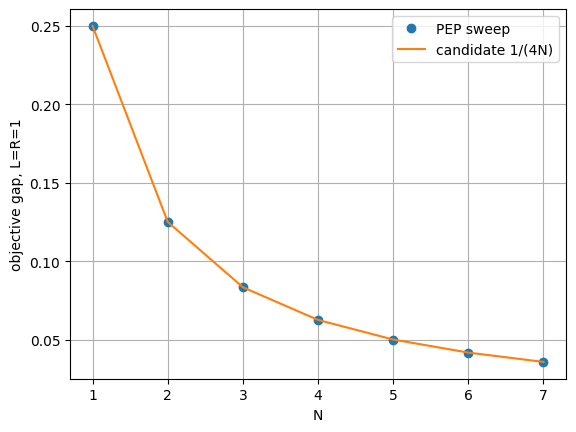

In [5]:
sweep = json.loads((notebook_dir / "state/pgm_b1.json").read_text())["sweep_results"]
for row in sweep:
    print(f"N={row['N']}: {row['opt_value']:.10f} ({row['status']})")
ns = [r["N"] for r in sweep]
values = [r["opt_value"] for r in sweep]
candidate = [1 / (4 * n) for n in ns]
print("Maximum absolute candidate residual:", max(abs(a-b) for a,b in zip(values,candidate)))
plt.plot(ns, values, "o", label="PEP sweep")
plt.plot(ns, candidate, "-", label="candidate 1/(4N)")
plt.xlabel("N")
plt.ylabel("objective gap, L=R=1")
plt.legend()
plt.grid(True)
plt.show()

The observed reciprocals are $4,8,12,16,20,24,28$, suggesting $h(x_N)-h(x_\star)\leq LR^2/(4N)$. Scaling the objective by $L$ and positions by $R$ gives the displayed dimensional factor; $R=0$ is the stationary case. This is a conjecture pending proof.

## Dense and relaxed proof solves
A dense CLARABEL solve was followed by dropping entries below $10^{-6}$, then the consecutive/optimizer relaxation shown below. The final certificate was captured from one primal solve with CLARABEL defaults. Saved values are replayed and checked without a new solve.

In [6]:
import hashlib
import json
import numpy as np
import sympy as sp
import pepflow as pf
from pepflow.utils import NUMERICAL_TYPE

b1 = json.loads((notebook_dir / 'state/pgm_b1.json').read_text())
dense = json.loads((notebook_dir / 'state/pgm_dense.json').read_text())
raw = json.loads((notebook_dir / 'state/pgm_selected_raw.json').read_text())
N_int = raw['N']
N = sp.Integer(N_int)
params_sp: dict[str, NUMERICAL_TYPE] = {'L': sp.Integer(1), 'R': sp.Integer(1)}
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
basis = ctx.basis_vectors()
assert raw['basis_vectors'] == [str(v) for v in basis]
assert raw['basis_scalars'] == [str(v) for v in ctx.basis_scalars()]
for name, digest in raw['source_hashes'].items():
    assert hashlib.sha256((notebook_dir / name).read_bytes()).hexdigest() == digest
print('Dense objective:', dense['opt_value'])
print('Basis:', raw['basis_vectors'])
for owner in ('f', 'g'):
    print('Dense active entries', owner, sum(v > 1e-6 for k,v in dense['named_dual_values'].items() if k.startswith(owner+':')))
print('Dense S rank (tol=1e-4):', np.linalg.matrix_rank(np.array(dense['S_matrix']), tol=1e-4))
# Relaxation recipe: retain only optimizer-to-iterate and forward consecutive pairs.
entries = list(pb.init_conditions)
for owner in (f, g):
    entries.extend(owner.get_interpolation_constraints(ctx))
def retained(name):
    if ':' not in name:
        return True
    left, right = name.split(':')[1].split(',')
    return left == 'x_star' or (right != 'x_star' and int(right[2:]) == int(left[2:]) + 1)
assert set(raw['relaxed_constraints']) == {c.name for c in entries if not retained(c.name)}
assert set(raw['named_dual_values']) == {c.name for c in entries}
print('Relaxed constraints dropped:', len(raw['relaxed_constraints']))
print('Selected objective:', raw['opt_value'], 'status:', raw['status'])
print('Dense/relaxed gap:', abs(dense['opt_value'] - raw['opt_value']))



Dense objective: 0.06249999907262903
Basis: ['x_0', 'x_star', 'grad_f(x_star)', 'grad_f(x_0)', 'grad_g(x_1)', 'grad_f(x_1)', 'grad_g(x_2)', 'grad_f(x_2)', 'grad_g(x_3)', 'grad_f(x_3)', 'grad_g(x_4)', 'grad_f(x_4)']
Dense active entries f 30
Dense active entries g 16
Dense S rank (tol=1e-4): 9
Relaxed constraints dropped: 34
Selected objective: 0.062499998838795916 status: optimal
Dense/relaxed gap: 2.33833112595061e-10


## Lambda and S verification
The candidate consecutive multipliers are $\alpha_i=i/(2N+1-i)$ for $f$ and $\beta_i=i/(2N-i)$ for $g$. Optimizer-row multipliers are differences of consecutive coefficients, with the terminal $f$ weight $1-\alpha_N$ and $\beta_N=1$. They are only numerical candidates here.
The supplied SOS is declared assistance. Its scale relative to this objective normalization is one. All three squared vectors per iteration are retained. The numerical certificate, candidate comparison, and full analytic proof have separate statuses.

In [7]:
# Candidate multipliers inferred from the selected consecutive-pair sample.
def lambda_candidate(owner, left, right, n):
    j = int(right[2:])
    def alpha(t):
        return sp.Rational(t, 2*n+1-t)
    def beta(t):
        return sp.Rational(t, 2*n-t)
    if owner == 'f':
        return alpha(j) if left != 'x_star' else (alpha(j+1)-alpha(j) if j<n else 1-alpha(n))
    return beta(j-1) if left != 'x_star' else beta(j)-beta(j-1)

lambda_errors = []
for owner in ('f', 'g'):
    labels = ['x_star'] + [f'x_{i}' for i in range(0 if owner == 'f' else 1,N_int+1)]
    candidate_matrix = np.zeros((len(labels), len(labels)))
    for row,left in enumerate(labels):
        for col,right in enumerate(labels):
            name = f'{owner}:{left},{right}'
            value = raw['named_dual_values'].get(name)
            if value is not None:
                candidate = lambda_candidate(owner,left,right,N_int)
                candidate_matrix[row,col] = float(candidate)
                lambda_errors.append(abs(float(candidate)-value))
                print(name, value, 'candidate', candidate)
    print('Candidate lambda', owner)
    pf.pprint_labeled_matrix(candidate_matrix, labels)
assert max(lambda_errors) <= 1e-4

# Supplied SOS aid, implemented in exact rational arithmetic.
def supplied_sos(ctx, n, smoothness):
    n = sp.Integer(n)
    smoothness = sp.sympify(smoothness)
    star = ctx['x_star']
    astar = f.grad(star)
    pieces, coefficients, vectors = [], [], []
    for i in range(1,int(n)+1):
        xp, x = ctx[f'x_{i-1}'], ctx[f'x_{i}']
        ap, a, s = f.grad(xp), f.grad(x), g.grad(x)
        c1 = n/((2*n+1-i)*(2*n-i)*smoothness)
        u1 = i/(2*n)*a+(2*n-i)/(2*n)*ap-astar
        c2 = ((i-1)/(2*n-i)*(2*n+2)/(2*n+1)+2*n/((2*n-i)**2*(2*n+1)))/(2*smoothness)
        u2 = ap+s-smoothness/(2*n+1-i)*(xp-star)
        c3 = i/(2*n+1-i)*(2*n)/(2*n+1)/(2*smoothness)
        u3 = (2*n+1)/(2*n)*(a+s)-(ap+s)/(2*n)-smoothness/(2*n-i)*(x-star)
        coefficients.extend([c1,c2,c3])
        vectors.extend([u1,u2,u3])
        pieces.append(c1*u1**2+c2*u2**2+c3*u3**2)
    return pieces, coefficients, vectors

pieces, coefficients, vectors = supplied_sos(ctx, N_int, 1)
S_candidate = sum(pieces, pf.Scalar.zero())
S_eval = pm.eval_scalar(S_candidate)
S_array = np.array(raw['S_matrix'])
D = np.diag(np.array(coefficients,dtype=float))
E = np.array([pm.eval_vector(v).coords for v in vectors],dtype=float)
S_reconstructed = E.T @ D @ E
assert np.all(np.array(coefficients,dtype=float) >= 0)
assert np.allclose(S_reconstructed,S_array,atol=1e-4,rtol=1e-5)
assert np.max(np.abs(np.array(S_eval.func_coords,dtype=float)),initial=0) == 0
assert float(S_eval.offset) == 0
print('Supplied aid normalization factor: 1')
print('SOS reconstruction residual:', np.max(np.abs(S_reconstructed-S_array)))
pf.pprint_labeled_matrix(S_reconstructed,raw['basis_vectors'])

# Complete numerical identity including initial constraint and both functions.
weighted = pf.Scalar.zero()
inequality_duals = []
for c in entries:
    value = raw['named_dual_values'][c.name]
    if raw['constraint_metadata'][c.name]['relaxed']:
        assert value is None
        continue
    assert value is not None
    assert c.cmp.value == 'LE'
    weighted += value * (c.lhs-c.rhs)
    inequality_duals.append(value)
diff = pm.eval_scalar(pb.performance_metric-raw['opt_value']-weighted+S_candidate)
def maxabs(x):
    return float(np.max(np.abs(np.asarray(x,dtype=float)),initial=0))
residuals = dict(identity_gram_max_abs=maxabs(diff.inner_prod_coords),identity_func_max_abs=maxabs(diff.func_coords),identity_offset_abs=maxabs(diff.offset),S_reconstruction_max_abs=maxabs(S_reconstructed-S_array),dense_relaxed_gap=abs(dense['opt_value']-raw['opt_value']),minimum_scalar_inequality_dual=min(inequality_duals),minimum_S_eigenvalue=float(np.linalg.eigvalsh(S_array).min()),minimum_matrix_inequality_eigenvalue=0.0)
assert raw['status'] == 'optimal'
assert all(residuals[k] <= 1e-5 for k in ('identity_gram_max_abs','identity_func_max_abs','identity_offset_abs'))
assert residuals['dense_relaxed_gap'] < 1e-5
assert residuals['minimum_scalar_inequality_dual'] >= -1e-6
assert residuals['minimum_S_eigenvalue'] >= -1e-6
assert np.allclose(S_array,S_array.T,atol=1e-6,rtol=0)
print('Complete numerical certificate checks:',residuals)
pf.pprint_labeled_matrix(np.asarray(diff.inner_prod_coords,dtype=float),raw['basis_vectors'])
# Independent candidate identity at this sample only; no all-horizon proof claim.
exact_weighted = sp.Rational(1,4*N_int)*(pb.init_conditions[0].lhs-pb.init_conditions[0].rhs)
for c in entries[1:]:
    if not raw['constraint_metadata'][c.name]['relaxed']:
        owner,pair = c.name.split(':')
        left,right = pair.split(',')
        exact_weighted += lambda_candidate(owner,left,right,N_int)*(c.lhs-c.rhs)
candidate_diff = pm.eval_scalar(pb.performance_metric-sp.Rational(1,4*N_int)-exact_weighted+S_candidate)
print('Candidate fixed-sample Gram residual:',maxabs(candidate_diff.inner_prod_coords))
print('Candidate fixed-sample function residual:',maxabs(candidate_diff.func_coords))
print('Candidate fixed-sample offset:',candidate_diff.offset)



f:x_star,x_0 0.1250000524780983 candidate 1/8
f:x_star,x_1 0.16071565747095803 candidate 9/56
f:x_star,x_2 0.21428742795473416 candidate 3/14
f:x_star,x_3 0.29999886259078856 candidate 3/10
f:x_star,x_4 0.1999980157025201 candidate 1/5
f:x_0,x_1 0.1250000524780985 candidate 1/8
f:x_1,x_2 0.2857157067096368 candidate 2/7
f:x_2,x_3 0.5000031314249512 candidate 1/2
f:x_3,x_4 0.8000019907763198 candidate 4/5
Candidate lambda f


<IPython.core.display.Math object>

g:x_star,x_1 0.1428546574437588 candidate 1/7
g:x_star,x_2 0.190480137093319 candidate 4/21
g:x_star,x_3 0.26666834784964005 candidate 4/15
g:x_star,x_4 0.39999687057096195 candidate 2/5
g:x_1,x_2 0.14285465744375864 candidate 1/7
g:x_2,x_3 0.3333347912976577 candidate 1/3
g:x_3,x_4 0.6000031359078778 candidate 3/5
Candidate lambda g


<IPython.core.display.Math object>

Supplied aid normalization factor: 1


SOS reconstruction residual: 3.135478371496525e-06


<IPython.core.display.Math object>

Complete numerical certificate checks: {'identity_gram_max_abs': 3.1391472977704282e-06, 'identity_func_max_abs': 1.619709921740764e-08, 'identity_offset_abs': 3.165652122383289e-09, 'S_reconstruction_max_abs': 3.135478371496525e-06, 'dense_relaxed_gap': 2.33833112595061e-10, 'minimum_scalar_inequality_dual': 0.06250000200444804, 'minimum_S_eigenvalue': 2.198704447512869e-09, 'minimum_matrix_inequality_eigenvalue': 0.0}


<IPython.core.display.Math object>

Candidate fixed-sample Gram residual: 1.1102230246251565e-16
Candidate fixed-sample function residual: 0.0
Candidate fixed-sample offset: 0


The complete fixed-horizon numerical certificate passes. The initial closed-form search found candidate lambda formulas and confirmed the supplied SOS numerically. The arbitrary-horizon identity and Lyapunov theorem remain unproved and are carried forward explicitly.

## Partial-sum Lyapunov construction and rank profile
Let $I^f_{u,v}\leq0$ and $I^g_{u,v}\leq0$ denote the normalized interpolation residuals, and $S_i\geq0$ the three-square piece supplied at iteration $i$. Set $V_0=0$, add the $f$ optimizer-to-zero term in the first increment, and thereafter accumulate
$$V_{k+1}-V_k=\sum_{c\text{ assigned to }k}\lambda_c I_c-S_{k+1}\leq0.$$
Each residual appears exactly once in the partial sums or boundary; the terminal smooth interpolation from the optimizer is retained as the single boundary term. All square pieces are subtracted. The numerical profile is rank four for every interior index at $N=4$ and $N=6$, with fixed exclusions of $V_0,V_N$. The terminal potential also retains the negative of the boundary smooth interpolation residual, in addition to the initial squared-distance normalization. Full-coordinate coverage is checked below. These finite-sample observations do not establish the analytic theorem.

In [8]:
def reconstruct_partial_sums(certificate):
    import json
    N_int = certificate['N_verify']
    params_sp = json.loads(certificate['params_json'])
    ctx, pb, obj = get_pep_setup(N_int, params_sp)
    pb.set_relaxed_constraints(certificate['relaxed_constraints'])
    REPO_ROOT = notebook_dir

    import hashlib
    import json
    from pathlib import Path
    import numpy as np
    import sympy as sp
    import pepflow as pf
    from pepflow.constraint import ScalarConstraint
    from pepflow.operator import LinearOperatorTranspose

    from pepflow.utils import name_to_vector_tuple

    certificate_checked = False
    if not certificate.get("numerical_certificate_verified", False):
        raise ValueError("Recover or verify the complete numerical certificate in Block 2")
    if not certificate.get("closed_form_search", {}).get("completed", False):
        raise ValueError("Complete or recover Block 2's initial closed-form attempt")
    certificate_keys = (
        "N_verify", "params_json", "relaxed_constraints",
        "S_matrix", "S_row_names", "S_col_names", "basis_vectors", "basis_scalars",
        "opt_value", "tau_sol", "tau_name", "named_dual_values", "constraint_metadata",
        "normalization", "certificate_provenance", "numerical_checks",
        "numerical_decomposition",
    )
    payload = {key: certificate[key] for key in certificate_keys}
    digest = hashlib.sha256(json.dumps(
        payload, sort_keys=True, separators=(",", ":"), allow_nan=False
    ).encode("utf-8")).hexdigest()
    if digest != certificate["certificate_id"]:
        raise ValueError("Certificate components changed; recover one coherent certificate")
    provenance = certificate["certificate_provenance"]
    if provenance["pep_type"] != "primal":
        raise ValueError("Recover and verify the certificate's actual dual sign convention")
    for relative_path, expected_hash in provenance["source_hashes"].items():
        source_path = (REPO_ROOT / relative_path).resolve()
        if not source_path.is_relative_to(REPO_ROOT):
            raise ValueError("Certificate source path must stay in the selected repository")
        if hashlib.sha256(source_path.read_bytes()).hexdigest() != expected_hash:
            raise ValueError(f"Certificate source changed: {relative_path}")
    if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
        raise ValueError("The imported PEPFlow source is not the selected repository")
    if N_int != certificate["N_verify"]:
        raise ValueError("Certificate horizon differs from the rebuilt setup")
    saved_params = json.loads(certificate["params_json"])
    expected_params = {
        key: (sp.Rational(value) if isinstance(value, str) else
              sp.nsimplify(value, rational=True, tolerance=1e-9)
              if isinstance(value, float) else sp.S(value))
        for key, value in saved_params.items()
    }
    if params_sp != expected_params:
        raise ValueError("Certificate parameters differ from the rebuilt setup")
    if not certificate["numerical_checks"]["passed"]:
        raise ValueError("Block 2 numerical checks did not pass")
    tol = certificate["numerical_checks"]["tolerances"]

    records = [(c, "initial", None, None) for c in pb.init_conditions]
    owners = list(ctx.func_to_triplets) + [
        owner for owner in ctx.oper_to_duplets
        if not isinstance(owner, LinearOperatorTranspose)
    ]
    for owner in owners:
        data = ctx.get_constraint_data(owner)
        for group, family in data.sc_dict.items():
            records.extend((c, "interpolation", str(owner), str(group)) for c in family)
        records.extend((c, "interpolation", str(owner), str(group))
                       for group, c in data.psd_dict.items())
    constraints_by_name = {c.name: c for c, _, _, _ in records}
    if len(constraints_by_name) != len(records):
        raise ValueError("Constraint names must identify one unique contribution")
    saved_meta = certificate["constraint_metadata"]
    saved_duals = certificate["named_dual_values"]
    if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(saved_meta):
        raise ValueError("The saved certificate does not cover the rebuilt constraints")
    relaxed = set(certificate["relaxed_constraints"])
    if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(constraints_by_name):
        raise ValueError("The selected relaxation differs from the saved certificate")
    if pb.ctx is not ctx:
        raise ValueError("The builder and expression context differ")
    basis = list(ctx.basis_vectors())
    basis_labels = [repr(v) for v in basis]
    scalar_labels = [repr(v) for v in ctx.basis_scalars()]
    if basis_labels != certificate["basis_vectors"] or scalar_labels != certificate["basis_scalars"]:
        raise ValueError("Certificate coordinate order differs from the rebuilt context")
    if certificate["S_row_names"] != basis_labels or certificate["S_col_names"] != basis_labels:
        raise ValueError("S labels do not match the rebuilt basis")
    S_array = np.asarray(certificate["S_matrix"], dtype=float)
    if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
        raise ValueError("Invalid S shape or entries")
    if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
        raise ValueError("S is not numerically symmetric")
    if len(basis) and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]:
        raise ValueError("S failed the recorded PSD tolerance")

    pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
    S_scalar = sum((float(S_array[i, j]) * basis[i] * basis[j]
                    for i, j in np.ndindex(S_array.shape)), pf.Scalar.zero())

    weighted_terms = {}
    interpolation_terms = {}
    interpolation_pairs = {}
    extra_terms = {}
    extra_duals = {}
    for constraint, origin, owner, group in records:
        name = constraint.name
        kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
        residual = constraint.lhs - constraint.rhs
        shape = [] if kind == "scalar" else list(np.shape(residual))
        expected_meta = dict(origin=origin, owner=owner, group=group, kind=kind,
                             comparator=constraint.cmp.value, shape=shape,
                             relaxed=name in relaxed)
        if any(saved_meta[name].get(key) != value for key, value in expected_meta.items()):
            raise ValueError(f"Constraint metadata changed: {name}")
        value = saved_duals[name]
        if name in relaxed:
            if value is not None:
                raise ValueError(f"A relaxed constraint must have no retained multiplier: {name}")
            continue
        if value is None:
            raise ValueError(f"Missing unrelaxed dual: {name}")
        dual = np.asarray(value, dtype=float)
        if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
            raise ValueError(f"Invalid saved dual: {name}")
        # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
        if constraint.cmp.name in ("GE", "SEQ"):
            residual = -residual
        if kind == "scalar":
            if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
                raise ValueError(f"Negative inequality multiplier: {name}")
            contribution = pf.Scalar.zero() + float(dual) * residual
        else:
            if constraint.cmp.name != "EQ" and not np.allclose(dual, dual.T, atol=tol["psd_tol"], rtol=0):
                raise ValueError(f"Nonsymmetric matrix dual: {name}")
            if constraint.cmp.name != "EQ" and dual.size and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]:
                raise ValueError(f"Matrix dual is not PSD: {name}")
            contribution = sum((float(dual[i, j]) * residual[j, i]
                                for i, j in np.ndindex(dual.shape)), pf.Scalar.zero())
        weighted_terms[name] = contribution
        if origin == "interpolation" and kind == "scalar":
            interpolation_terms[name] = contribution
            try:
                interpolation_pairs[name] = name_to_vector_tuple(name)
            except (ValueError, IndexError):
                interpolation_pairs[name] = None  # Assign this term explicitly when grouping.
        elif name != certificate["tau_name"]:
            extra_terms[name] = contribution
            extra_duals[name] = value

    tau_name = certificate["tau_name"]
    if (tau_name not in weighted_terms or saved_meta[tau_name]["origin"] != "initial"
            or saved_meta[tau_name]["kind"] != "scalar" or tau_name in relaxed
            or certificate["normalization"]["tau_name"] != tau_name):
        raise ValueError("Missing or inconsistent bound normalization constraint")
    if not np.allclose(saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0):
        raise ValueError("The saved normalization dual is inconsistent")
    if not np.isfinite(certificate["opt_value"]) or not np.allclose(
        certificate["normalization"]["bound_value"], certificate["opt_value"],
        atol=tol["identity_atol"], rtol=tol["identity_rtol"]
    ):
        raise ValueError("The saved bound/normalization is inconsistent")
    certificate_diff = (pb.performance_metric - float(certificate["opt_value"])
                        - sum(weighted_terms.values(), pf.Scalar.zero()) + S_scalar)
    evaluated_diff = pm.eval_scalar(certificate_diff)
    for label, coords in (
        ("Gram", evaluated_diff.inner_prod_coords),
        ("function", evaluated_diff.func_coords),
        ("offset", np.asarray(evaluated_diff.offset)),
    ):
        if not np.allclose(np.asarray(coords, dtype=float), 0,
                           atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
            raise ValueError(f"Numerical certificate {label} identity failed")
    decomposition = certificate["numerical_decomposition"]
    D_saved = np.asarray(decomposition["D"], dtype=float)
    E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
    if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
        raise ValueError("Numerical S decomposition basis differs")
    if E_saved.shape[1] != len(basis) or D_saved.shape != (E_saved.shape[0], E_saved.shape[0]):
        raise ValueError("Numerical S decomposition shape differs")
    if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
        raise ValueError("Numerical S decomposition contains nonfinite values")
    if not np.allclose(E_saved.T @ D_saved @ E_saved, S_array,
                       atol=tol["reconstruction_atol"], rtol=tol["reconstruction_rtol"]):
        raise ValueError("Numerical S decomposition does not reconstruct this certificate")
    certificate_checked = True
    print("Numerical certificate checked for this N and parameter sample.")

    # Direct pieces from the B2 aid, each a sum of three nonnegative squares.
    pieces, coefficients, vectors = supplied_sos(ctx, N_int, 1)
    S_piece_terms = {f'S_{i+1}':piece for i,piece in enumerate(pieces)}
    S_assignment = {name:i for i,name in enumerate(S_piece_terms)}
    # With interpolation residuals <= 0, every assigned contribution minus its
    # nonnegative S piece gives a nonpositive increment.
    group_terms = {name:term for name,term in weighted_terms.items() if name != tau_name}
    term_assignment = {}
    for name in group_terms:
        left, right = name.split(':')[1].split(',')
        term_assignment[name] = 'boundary' if name == f'f:x_star,x_{N_int}' else int(right[2:])-1
    assert set(term_assignment) == set(group_terms)
    assert set(S_assignment) == set(S_piece_terms)
    lyap = [pf.Scalar.zero()]
    partial_sum = sum((term for name,term in group_terms.items() if term_assignment[name] == -1), pf.Scalar.zero())
    for step in range(N_int):
        partial_sum += sum((term for name,term in group_terms.items() if term_assignment[name] == step), pf.Scalar.zero())
        partial_sum -= S_piece_terms[f'S_{step+1}']
        lyap.append(partial_sum)
    rank_tolerance = 1e-4
    rank_left, rank_right = 1, 1
    ranks, singular_values = [], []
    for k, value in enumerate(lyap):
        matrix = pm.eval_scalar(value).inner_prod_coords.astype(float)
        singular_values.append(np.linalg.svd(matrix,compute_uv=False).tolist())
        rank = int(np.linalg.matrix_rank(matrix,tol=rank_tolerance))
        ranks.append(rank)
        print(f'rank V_{k}: {rank}')
        if k == 0:
            print()
    retained_ranks = ranks[rank_left:N_int+1-rank_right]
    print('Interior rank is constant at this N:', len(retained_ranks)>=3 and len(set(retained_ranks))==1,'boundary exclusions:',(rank_left,rank_right))
    assert len(retained_ranks)>=3 and len(set(retained_ranks))==1
    # Credibility check records all singular values, including numerical residuals.
    # No retained singular value lies in [tolerance/2, 2*tolerance].
    rank_credible = all(not any(5e-5 <= v <= 2e-4 for v in singular_values[k]) for k in range(1,N_int))
    assert rank_credible



    boundary_names = [name for name, step in term_assignment.items() if step == "boundary"]
    boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
    if sum(name in interpolation_terms for name in boundary_names) > 1 or len(boundary_S) > 1:
        raise ValueError("Revisit the permitted terminal interpolation/S leftovers")
    omitted = sum((group_terms[name] for name, step in term_assignment.items()
                   if step == "omitted"), pf.Scalar.zero())
    leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
    leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
    coverage_diff = (lyap[N_int] + leftover + omitted
                     - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar))
    piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
    for label, expression in (("coverage", coverage_diff), ("S pieces", piece_diff), ("omitted", omitted)):
        value = pm.eval_scalar(expression)
        for coords in (value.inner_prod_coords, value.func_coords, np.asarray(value.offset)):
            if not np.allclose(np.asarray(coords, dtype=float), 0,
                               atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
                raise ValueError(f"Full-coordinate {label} check failed")
    # Every subtracted S piece must have the nonnegative numerical sign used here.
    for name, piece in S_piece_terms.items():
        value = pm.eval_scalar(piece)
        matrix = np.asarray(value.inner_prod_coords, dtype=float)
        if not np.allclose(value.func_coords, 0, atol=tol["identity_atol"], rtol=0) or not np.allclose(value.offset, 0, atol=tol["identity_atol"], rtol=0):
            raise ValueError(f"S piece has unexpected function/offset terms: {name}")
        if matrix.size and np.linalg.eigvalsh((matrix + matrix.T) / 2).min() < -tol["psd_tol"]:
            raise ValueError(f"S piece has the wrong numerical sign: {name}")
    # Step identities follow the chosen assignments; check them, including the initial terms.
    for k in range(N_int):
        assigned_steps = {-1, 0} if k == 0 else {k}
        increment = sum((group_terms[name] for name, step in term_assignment.items()
                         if step in assigned_steps), pf.Scalar.zero())
        increment -= sum((S_piece_terms[name] for name, step in S_assignment.items()
                          if step in assigned_steps), pf.Scalar.zero())
        value = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
        for coords in (value.inner_prod_coords, value.func_coords, np.asarray(value.offset)):
            if not np.allclose(np.asarray(coords, dtype=float), 0,
                               atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
                raise ValueError(f"Partial-sum increment identity failed at k={k}")
    grouping_checked = True
    M_final = pm.eval_scalar(lyap[N_int]).inner_prod_coords.astype(float)
    rank_final = int(np.linalg.matrix_rank(M_final, tol=rank_tolerance))
    print(f"lyap[{N_int}] rank:", rank_final)
    print("Coverage checked with all scalar components and explicit boundary leftovers.")

    evaluated = [pm.eval_scalar(value) for value in lyap]
    observation = dict(N=N_int,certificate_id=certificate['certificate_id'],recipe_id='forward_star_consecutive_terminal_f_boundary',rank_profile=ranks,rank_convention={'tolerance':1e-4,'scaling':'unscaled Gram coordinates','order':'setup basis order'},rank_credible=rank_credible,certificate_checked=certificate_checked,grouping_checked=grouping_checked,singular_values=singular_values)
    return dict(observation=observation,lyap_inner_prod_coords=[np.array(v.inner_prod_coords,dtype=float).tolist() for v in evaluated],lyap_func_coords=[np.array(v.func_coords,dtype=float).tolist() for v in evaluated],lyap_offsets=[float(v.offset) for v in evaluated],grouping_coverage=dict(constraint_assignment=term_assignment,S_assignment=S_assignment,normalization_constraint=tau_name,boundary_constraints=boundary_names,boundary_S=boundary_S,omitted_constraints=[],checked=True),extra_duals=extra_duals)


In [9]:
certificate = json.loads((notebook_dir/'state/pgm_b2.json').read_text())
other_certificate = json.loads((notebook_dir/'supplementary/b2-N6-certificate.json').read_text())
print('Selected horizon:', certificate['N_verify'])
selected_partial_sums = reconstruct_partial_sums(certificate)
print('Confirmation horizon:', other_certificate['N_verify'])
other_partial_sums = reconstruct_partial_sums(other_certificate)
rank_samples = [selected_partial_sums['observation'],other_partial_sums['observation']]
assert len({sample['N'] for sample in rank_samples}) == 2
assert all(sample['rank_profile'][1:sample['N']] == [4]*(sample['N']-1) for sample in rank_samples)
assert all(sample['certificate_checked'] and sample['grouping_checked'] and sample['rank_credible'] for sample in rank_samples)
print('Cross-horizon confirmation: N=4,6; interior rank 4; exclusions (1,1); unscaled tolerance 1e-4.')


Selected horizon: 4
Numerical certificate checked for this N and parameter sample.
rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
lyap[4] rank: 4
Coverage checked with all scalar components and explicit boundary leftovers.
Confirmation horizon: 6


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\pgm_with_sos\r04\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



Numerical certificate checked for this N and parameter sample.


rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
lyap[6] rank: 4
Coverage checked with all scalar components and explicit boundary leftovers.
Cross-horizon confirmation: N=4,6; interior rank 4; exclusions (1,1); unscaled tolerance 1e-4.


## Identify the vectors composing the Lyapunov function
Pending Block 4.

## Coefficient extraction and closed-form Lyapunov function
Pending Blocks 4–5.

## Symbolic step, base, and boundary identities
Pending Block 5.